# Séance 4 : Solutions des Travaux Dirigés (Best Estimate Vie)
**Module :** Actuariat Vie & Solvabilité 2
**Auteur :** Fabrice BOREL-MATHURIN

Ce notebook rassemble les corrections des exercices de la Séance 4 :
1.  **Exercice 4.1 :** Projection d'un contrat d'épargne en euros (Modèle complet)
2.  **Exercice 4.2 :** Valorisation d'une temporaire décès
3.  **Exercice 4.3 :** Valorisation d'une garantie plancher sur UC
4.  **Bonus :** Exemples numériques du cours (Rachats dynamiques, PB)

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Configuration pour l'affichage
pd.set_option('display.max_columns', None)
pd.set_option('display.width', 1000)

print("Environnement chargé avec succès.")

Environnement chargé avec succès.


3. Exercice 4.1 : Projection Contrat Épargne Euros
Cet exercice correspond au script complet présenté dans les slides 34 à 36. Il modélise la projection année par année des flux d'un contrat d'épargne classique.

In [6]:
def calculer_BE_contrat_epargne(
    age_initial, PM_initiale, duree, primes_annuelles,
    table_mortalite, loi_rachat, TMG, taux_frais, 
    courbe_actualisation, inflation_frais=0.02
):
    """
    Projette les flux d'un contrat épargne euros et calcule le BE.
    Source : Slides 34-36 du cours.
    """
    # Initialisation
    resultats = []
    PM = PM_initiale
    nb_tetes = 1.0
    
    for t in range(1, duree + 1):
        age = age_initial + t - 1
        
        # Récupération des hypothèses pour l'année t
        # Gestion des indices : si la table n'a pas l'âge, on prend 1 (décès certain) par sécurité
        qx_deces = table_mortalite.get(age, 1.0)
        qx_rachat = loi_rachat[t-1] if t-1 < len(loi_rachat) else 0.0
        taux_actu = courbe_actualisation[t-1] if t-1 < len(courbe_actualisation) else 0.02
        
        # Calcul des Flux Sortants (Prestations + Frais)
        deces = PM * qx_deces * nb_tetes
        rachats = PM * qx_rachat * nb_tetes
        frais = PM * taux_frais * nb_tetes * (1 + inflation_frais)**(t-1)
        
        # Flux Entrants (Primes)
        primes = primes_annuelles * nb_tetes
        
        # Flux Net de l'année t
        flux_net = deces + rachats + frais - primes
        
        # Actualisation
        facteur_actu = 1 / (1 + taux_actu)**t
        flux_actu = flux_net * facteur_actu
        
        # Mise à jour des variables d'état (PM et Population) pour t+1
        if nb_tetes > 0:
            # Évolution PM : (Stock début + Primes - Sorties) * (1 + TMG)
            # Note : On divise par nb_tetes pour raisonner sur la PM unitaire moyenne
            PM = (PM + primes_annuelles - deces/nb_tetes 
                  - rachats/nb_tetes - frais/nb_tetes) * (1 + TMG)
        
        # La population diminue des décès et des rachats
        nb_tetes *= (1 - qx_deces) * (1 - qx_rachat)
        
        # Stockage
        resultats.append({
            'annee': t, 'age': age, 'nb_tetes': nb_tetes,
            'PM_fin': PM, 'flux_net': flux_net, 'flux_actu': flux_actu
        })
    
    df = pd.DataFrame(resultats)
    BE = df['flux_actu'].sum()
    
    return df, BE

=== RÉSULTAT EXERCICE 4.1 ===
Best Estimate calculé : 38,426.46 €

Aperçu des 5 premières années :


,annee,age,nb_tetes,PM_fin,flux_net,flux_actu
0,1,30,0.849778,87466.491281,13826.116965,13488.894600
1,2,31,0.722107,76742.165524,10077.046959,9591.478366
2,3,32,0.649697,71461.773548,4575.614280,4248.912725
3,4,33,0.584533,66670.461357,3753.033556,3400.063170
4,5,34,0.549264,65029.958571,1520.684614,1344.063616


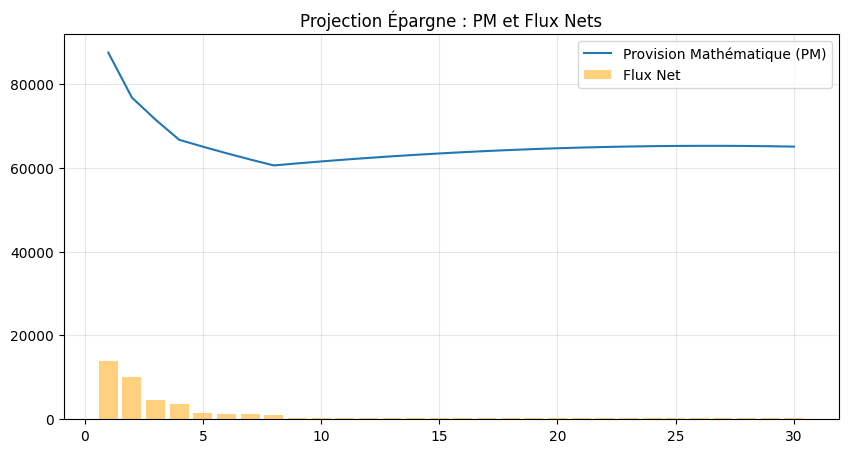

In [7]:
# --- Paramètres de l'exercice ---
# Création d'une table de mortalité simplifiée (Loi de Makeham)
ages = range(18, 110)
table_mortalite = {x: 0.0001 * np.exp(0.08 * (x - 18)) for x in ages}

# Loi de rachat dégressive (15% début, puis 3%)
loi_rachat = np.array([0.15]*2 + [0.10]*2 + [0.06]*4 + [0.03]*30)

# Courbe des taux plate à 2.5%
courbe_actu = np.full(40, 0.025)

# Lancement de la projection
df_flux, BE_total = calculer_BE_contrat_epargne(
    age_initial=30, 
    PM_initiale=100_000, 
    duree=30,
    primes_annuelles=2_000, 
    table_mortalite=table_mortalite,
    loi_rachat=loi_rachat, 
    TMG=0.015,       # TMG 1.5%
    taux_frais=0.008, # Frais 0.8%
    courbe_actualisation=courbe_actu
)

print(f"=== RÉSULTAT EXERCICE 4.1 ===")
print(f"Best Estimate calculé : {BE_total:,.2f} €")
print("\nAperçu des 5 premières années :")
display(df_flux.head())

# Visualisation
plt.figure(figsize=(10, 5))
plt.plot(df_flux['annee'], df_flux['PM_fin'], label='Provision Mathématique (PM)')
plt.bar(df_flux['annee'], df_flux['flux_net'], color='orange', alpha=0.5, label='Flux Net')
plt.title('Projection Épargne : PM et Flux Nets')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

4. Exercice 4.2 : Contrat Décès Temporaire
Solution basée sur la formule présentée Slide 16. Garantie : Capital versé si décès avant l'échéance. Risque : Surmortalité

In [8]:
def calculer_BE_deces_temporaire(K, P, age, duree, table_mort, taux_resil, courbe_taux):
    """
    Calcule le BE d'une temporaire décès.
    K: Capital garanti
    P: Prime annuelle
    taux_resil: Taux de chute (résiliation)
    """
    be_total = 0
    prob_survie_cumul = 1.0  # t-1_p_x
    
    print(f"Analyse des flux (Décès Temporaire sur {duree} ans) :")
    
    for t in range(1, duree + 1):
        # Probabilités de l'année
        q_d = table_mort.get(age + t - 1, 0.005) # Taux décès
        
        # Flux Sortant (Prestations Décès)
        # On paie K si la personne survit jusqu'à t-1 puis décède en t
        flux_deces = K * prob_survie_cumul * q_d
        
        # Flux Entrant (Primes)
        # On reçoit P si la personne survit jusqu'à t-1 et ne résilie pas
        # Note : Le terme (1-l)^(t-1) modélise la résiliation cumulée
        flux_prime = P * prob_survie_cumul * ((1 - taux_resil)**(t-1))
        
        # Actualisation
        df = 1 / (1 + courbe_taux[t-1])**t
        flux_net_actu = (flux_deces - flux_prime) * df
        
        be_total += flux_net_actu
        
        # Mise à jour survie pour l'itération suivante
        prob_survie_cumul *= (1 - q_d)
        
    return be_total

# Application numérique
be_deces = calculer_BE_deces_temporaire(
    K=150_000, P=300, age=40, duree=15,
    table_mort=table_mortalite, taux_resil=0.05, courbe_taux=courbe_actu
)

print(f"\n=== RÉSULTAT EXERCICE 4.2 ===")
print(f"Best Estimate Décès Temporaire : {be_deces:,.2f} €")

Analyse des flux (Décès Temporaire sur 15 ans) :

=== RÉSULTAT EXERCICE 4.2 ===
Best Estimate Décès Temporaire : -788.27 €


5. Exercice 4.3 : Contrat UC avec Garantie Plancher
Solution basée sur le mécanisme décrit Slide 14 et l'exemple Slide 15. Garantie : L'assureur paie Max(0, Garantie - Valeur_Fonds) en cas de décès.

=== RÉSULTAT EXERCICE 4.3 ===
Coût total de la garantie (BE) : 339.06 €


,t,Valeur_UC,Cout_Garantie
0,1,96030.000000,5.135519
1,2,92217.609000,10.891516
2,3,88556.569923,17.324713
3,4,85040.874097,24.496262
4,5,81664.751395,32.472012
5,6,78422.660765,41.322776
6,7,75309.281132,51.124607
7,8,72319.502671,61.959063
8,9,69448.418415,73.913467
9,10,66691.316204,87.081151


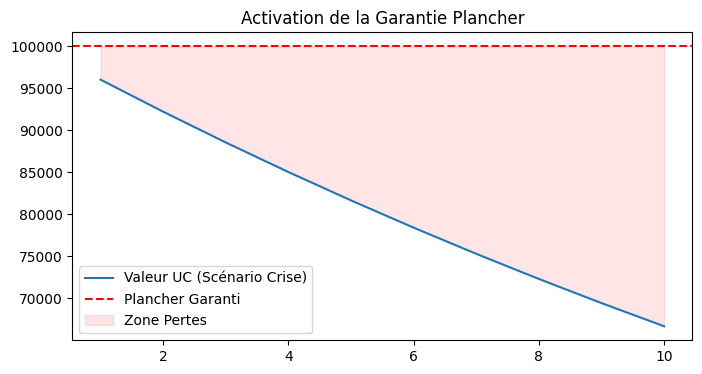

In [9]:
def calculer_cout_garantie_plancher(V0, Garantie, age, duree, r_uc, f_uc, table_mort, courbe_taux):
    """
    Calcule le coût technique (BE) de la garantie plancher en cas de décès.
    Scénario déterministe unique (ex: krach boursier).
    """
    cout_total_actu = 0
    V_t = V0
    nb_tetes = 1.0
    data = []
    
    for t in range(1, duree + 1):
        # 1. Évolution du fonds UC (Formule Slide 14)
        V_t = V_t * (1 - f_uc) * (1 + r_uc)
        
        # 2. Calcul du coût de la garantie
        # Si V_t < Garantie, l'assureur paie la différence pour les décès de l'année
        q_d = table_mort.get(age + t - 1, 0.001)
        nb_deces = nb_tetes * q_d
        
        perte_unitaire = max(0, Garantie - V_t)
        cout_annee = perte_unitaire * nb_deces
        
        # 3. Actualisation
        df = 1 / (1 + courbe_taux[t-1])**t
        cout_actu = cout_annee * df
        cout_total_actu += cout_actu
        
        # Mise à jour population
        nb_tetes *= (1 - q_d)
        
        data.append({'t': t, 'Valeur_UC': V_t, 'Cout_Garantie': cout_annee})
        
    return pd.DataFrame(data), cout_total_actu

# Application numérique (Scénario de crise Slide 15)
# Fonds perd 3% par an, Frais UC 1%, Garantie 100k€
df_uc, cout_garantie = calculer_cout_garantie_plancher(
    V0=100_000, Garantie=100_000, 
    age=50, duree=10, 
    r_uc=-0.03, f_uc=0.01, 
    table_mort=table_mortalite, courbe_taux=courbe_actu
)

print(f"=== RÉSULTAT EXERCICE 4.3 ===")
print(f"Coût total de la garantie (BE) : {cout_garantie:,.2f} €")
display(df_uc)

# Graphique
plt.figure(figsize=(8, 4))
plt.plot(df_uc['t'], df_uc['Valeur_UC'], label='Valeur UC (Scénario Crise)')
plt.axhline(y=100_000, color='r', linestyle='--', label='Plancher Garanti')
plt.fill_between(df_uc['t'], df_uc['Valeur_UC'], 100_000, 
                 where=(df_uc['Valeur_UC'] < 100_000), color='red', alpha=0.1, label='Zone Pertes')
plt.title('Activation de la Garantie Plancher')
plt.legend()
plt.show()

Bonus : Rachats Dynamiques
Exemple de la Slide 24: Impact de la hausse des taux sur les rachats.

In [10]:
def calcul_rachat_dynamique(taux_base, taux_contrat, taux_marche, elasticite=3):
    """
    Calcule le taux de rachat dynamique selon la loi :
    q = q_base * (1 + beta * max(0, (r_m - r_c)/r_c))
    """
    delta = max(0, (taux_marche - taux_contrat) / taux_contrat)
    q_dynamique = taux_base * (1 + elasticite * delta)
    return q_dynamique, delta

# Paramètres de l'exemple Slide 24
q_base = 0.03
r_contrat = 0.015
r_marche = 0.04
beta = 3

q_dyn, delta = calcul_rachat_dynamique(q_base, r_contrat, r_marche, beta)

print(f"=== BONUS : RACHATS DYNAMIQUES ===")
print(f"Écart relatif de taux (Delta) : {delta:.2%}")
print(f"Taux de rachat de base : {q_base:.1%}")
print(f"Taux de rachat dynamique calculé : {q_dyn:.1%} (x{q_dyn/q_base:.0f})")

=== BONUS : RACHATS DYNAMIQUES ===
Écart relatif de taux (Delta) : 166.67%
Taux de rachat de base : 3.0%
Taux de rachat dynamique calculé : 18.0% (x6)


3. Exercice 4.1 : Projection Contrat Épargne Euros
Cet exercice correspond au script complet présenté dans les slides 34 à 36. Il modélise la projection année par année des flux d'un contrat d'épargne classique

In [3]:
def calculer_BE_contrat_epargne(
    age_initial, PM_initiale, duree, primes_annuelles,
    table_mortalite, loi_rachat, TMG, taux_frais, 
    courbe_actualisation, inflation_frais=0.02
):
    """
    Projette les flux d'un contrat épargne euros et calcule le BE.
    Source : Slides 34-36 du cours.
    """
    # Initialisation
    resultats = []
    PM = PM_initiale
    nb_tetes = 1.0
    
    for t in range(1, duree + 1):
        age = age_initial + t - 1
        
        # Récupération des hypothèses pour l'année t
        # Gestion des indices : si la table n'a pas l'âge, on prend 1 (décès certain) par sécurité
        qx_deces = table_mortalite.get(age, 1.0)
        qx_rachat = loi_rachat[t-1] if t-1 < len(loi_rachat) else 0.0
        taux_actu = courbe_actualisation[t-1] if t-1 < len(courbe_actualisation) else 0.02
        
        # Calcul des Flux Sortants (Prestations + Frais)
        deces = PM * qx_deces * nb_tetes
        rachats = PM * qx_rachat * nb_tetes
        frais = PM * taux_frais * nb_tetes * (1 + inflation_frais)**(t-1)
        
        # Flux Entrants (Primes)
        primes = primes_annuelles * nb_tetes
        
        # Flux Net de l'année t
        flux_net = deces + rachats + frais - primes
        
        # Actualisation
        facteur_actu = 1 / (1 + taux_actu)**t
        flux_actu = flux_net * facteur_actu
        
        # Mise à jour des variables d'état (PM et Population) pour t+1
        if nb_tetes > 0:
            # Évolution PM : (Stock début + Primes - Sorties) * (1 + TMG)
            # Note : On divise par nb_tetes pour raisonner sur la PM unitaire moyenne
            PM = (PM + primes_annuelles - deces/nb_tetes 
                  - rachats/nb_tetes - frais/nb_tetes) * (1 + TMG)
        
        # La population diminue des décès et des rachats
        nb_tetes *= (1 - qx_deces) * (1 - qx_rachat)
        
        # Stockage
        resultats.append({
            'annee': t, 'age': age, 'nb_tetes': nb_tetes,
            'PM_fin': PM, 'flux_net': flux_net, 'flux_actu': flux_actu
        })
    
    df = pd.DataFrame(resultats)
    BE = df['flux_actu'].sum()
    
    return df, BE

In [4]:
# --- Paramètres de l'exercice ---
# Création d'une table de mortalité simplifiée (Loi de Makeham)
ages = range(18, 110)
table_mortalite = {x: 0.0001 * np.exp(0.08 * (x - 18)) for x in ages}

# Loi de rachat dégressive (15% début, puis 3%)
loi_rachat = np.array([0.15]*2 + [0.10]*2 + [0.06]*4 + [0.03]*30)

# Courbe des taux plate à 2.5%
courbe_actu = np.full(40, 0.025)

# Lancement de la projection
df_flux, BE_total = calculer_BE_contrat_epargne(
    age_initial=30, 
    PM_initiale=100_000, 
    duree=30,
    primes_annuelles=2_000, 
    table_mortalite=table_mortalite,
    loi_rachat=loi_rachat, 
    TMG=0.015,       # TMG 1.5%
    taux_frais=0.008, # Frais 0.8%
    courbe_actualisation=courbe_actu
)

print(f"=== RÉSULTAT EXERCICE 4.1 ===")
print(f"Best Estimate calculé : {BE_total:,.2f} €")
print("\nAperçu des 5 premières années :")
display(df_flux.head())

# Visualisation
plt.figure(figsize=(10, 5))
plt.plot(df_flux['annee'], df_flux['PM_fin'], label='Provision Mathématique (PM)')
plt.bar(df_flux['annee'], df_flux['flux_net'], color='orange', alpha=0.5, label='Flux Net')
plt.title('Projection Épargne : PM et Flux Nets')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

NameError: name 'np' is not defined